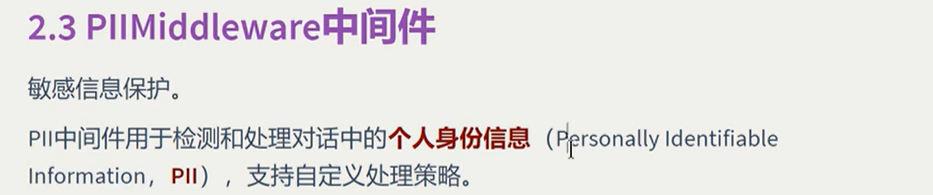
## 举例1，使用内置检测器


In [6]:
from langchain_core import messages
from langchain.agents.middleware import SummarizationMiddleware, PIIMiddleware
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
from utils.tool_utils import query_weather_from_web,query_news_from_web

# 1.初始化模型给中间件使用，不是agent
model = ChatOpenAI(
    # model="qwen3-vl:latest",
    # model="483025889/qwen3.5:9b",
    model="gemma4:12b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)

# 2.创建agent对象
agent = create_agent(
    model=model,
    middleware=[
        PIIMiddleware("email",strategy='redact',apply_to_input=True),
        PIIMiddleware("credit_card",strategy='mask',apply_to_input=True),
        PIIMiddleware("url",strategy='hash',apply_to_input=True),
        PIIMiddleware("mac_address",strategy='mask',apply_to_input=True),
        PIIMiddleware("ip",strategy='block',apply_to_input=True),
    ]
)

# 3.调用agent
resp = agent.invoke({"messages":[
    HumanMessage("""
      帮我向 156168188@qq.com 发送一封邮件
      同时查看银行卡号：5105-1051-0510-5100 的余额
      访问 https://localhost:12345
      确认这是不是 MAC地址： 11-11-11-11-11-11
    """)
]})

for msg in resp["messages"]:
    msg.pretty_print()

try: 
    resp1 = agent.invoke({"messages":[HumanMessage("看看这个 IP 能不能ping通： 192.168.10.1")]})
except Exception as e:
    print("="*30,'->抛异常<-',"="*30)
    print(f"检测到IP,抛异常：{e}")


================================ Human Message =================================


      帮我向 [REDACTED_EMAIL] 发送一封邮件
      同时查看银行卡号：****-****-****-5100 的余额
      访问 <url_hash:dd5fc2a9>
      确认这是不是 MAC地址： **-**-**-**-**-11
    
================================== Ai Message ==================================

很抱歉，作为一个人工智能语言模型，我**无法**执行您要求的这些操作。以下是具体原因：

1.  **发送邮件**：我没有权限访问您的电子邮件账户，也没有发送电子邮件的工具或功能。
2.  **查看银行卡余额**：出于安全和隐私保护的考虑，我无法访问任何银行账户、个人财务信息或支付系统。**请切勿在任何 AI 对话框中输入真实的银行卡号或密码。**
3.  **访问 URL**：我无法直接访问外部互联网上的特定链接（URL），除非该网页的内容被直接提供在对话中或通过特定的工具接口提供给我。
4.  **确认 MAC 地址**：如果您能提供完整的 MAC 地址字符串（例如 `00:1A:2B:3C:4D:5E`），我可以告诉您它的格式是否符合标准的 MAC 地址规范。

**总结：**
我无法完成除了分析信息以外的任何涉及外部操作（邮件、银行、网页访问）的任务。如果您有关于这些主题的**文字内容**需要我分析或润色，请直接发送到对话框中。
============================== ->抛异常<- ==============================
检测到IP,抛异常：Detected 1 instance(s) of ip in text content


## 举例2.使用自定义检测器


In [7]:
import re

# 自定义检测函数
def detect_phone_number(content: str):
    return [
        {
            "text":m.group(0),# 提取出具体匹配到的11位数字文本(例如：13800138000)
            "start":m.start(), # 起始索引位置（从0开始）
            "end":m.end()  # 结束索引位置
        } for m in re.finditer(r"[0-9]{11}",content)
    ]

agent = create_agent(
    model=model,
    middleware=[
        PIIMiddleware("api_key",strategy='hash',apply_to_input=True,detector=r"sk-[a-zA-Z0-9]+"),
        PIIMiddleware("phone_number",strategy='mask',apply_to_input=True,detector=detect_phone_number),
    ]
)

resp = agent.invoke({"messages":[
    HumanMessage("""
    这是不是有效的API_KEY: sk-awef23AFEfaafaefa
    帮我给这个号码打电话： 12345612345
    访问 https://localhost:12345
    """)
]})

for msg in resp["messages"]:
    msg.pretty_print()

================================ Human Message =================================


    这是不是有效的API_KEY: <api_key_hash:6c678cc0>
    帮我给这个号码打电话： ****2345
    访问 https://localhost:12345
    
================================== Ai Message ==================================

针对您提出的三个请求，我需要分别说明：

### 1. 关于 API_KEY 的有效性
**我无法验证该 API_KEY 是否有效。**
作为人工智能，我没有权限访问任何特定的第三方服务商（如 OpenAI, Google, AWS 等）或私人数据库来校验密钥、哈希值或 Token。此外，为了您的账户安全，**请切勿在任何公共对话框中分享真实的 API_KEY**。

### 2. 关于拨打电话
**我无法直接为您拨打电话。**
我是一个人工智能语言模型，目前没有内置拨号功能，也没有权限直接操作电信网络或您的手机/电话系统。

### 3. 关于访问 https://localhost:12345
**我无法访问该链接。**
*   **原因一：** `localhost` 指的是**您的本地计算机**。因为我运行在云端服务器上，我无法进入您的私人内网或访问您的电脑端口。
*   **原因二：** 即使是公网链接，我的功能主要集中在处理文本、代码和数据，通常无法像浏览器一样去“访问”并实时交互复杂的网页界面（除非通过特定的插件或工具接口）。

---
**总结：** 我无法完成您提到的这些操作。如果您是在调试代码或配置环境，建议您检查本地服务器状态，并查看对应的 API 文档来验证密钥。
